## Build A basic Chatboat with langgraph(Graph API)

In [28]:
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [29]:
class State(TypedDict):
    messages:Annotated[list,add_messages]

graph_builder=StateGraph(State)

In [30]:
graph_builder

In [31]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

In [32]:

from langchain.chat_models import init_chat_model

llm = init_chat_model(
    model="openai/gpt-oss-20b",
    model_provider="groq",
    temperature=0
)

response = llm.invoke("Hi")
print(response.content)

Hello! How can I help you today?


In [33]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.10', 'langchain': '1.4.4'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001F8AC954910>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001F8AC955310>, model_name='openai/gpt-oss-20b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********'))

In [34]:
# Node Functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

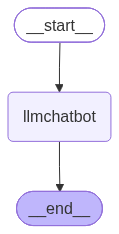

Hello! How can I help you today?


In [35]:

from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage
from IPython.display import Image, display


# 1. Define State
class State(TypedDict):
    messages: Annotated[list, add_messages]


# 2. Define chatbot node
def chatbot(state: State):
    # llm must be initialized before using this code
    response = llm.invoke(state["messages"])
    return {"messages": [response]}


# 3. Build graph
graph_builder = StateGraph(State)

graph_builder.add_node("llmchatbot", chatbot)

graph_builder.add_edge(START, "llmchatbot")
graph_builder.add_edge("llmchatbot", END)


# 4. Compile graph
graph = graph_builder.compile()


# 5. Visualize graph
display(Image(graph.get_graph().draw_mermaid_png()))


# 6. Invoke graph
response = graph.invoke({
    "messages": [HumanMessage(content="Hi")]
})
response["messages"]
print(response["messages"][-1].content)


In [36]:
for event in graph.stream({"messages": "Hi How are you?"}):
    for value in event.values():
        print(value)

{'messages': [AIMessage(content="Hello! I'm just a bunch of code, but I'm here and ready to help. How can I assist you today?", additional_kwargs={'reasoning_content': 'User says "Hi How are you?" It\'s a greeting. We should respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 51, 'prompt_tokens': 76, 'total_tokens': 127, 'completion_time': 0.053588003, 'completion_tokens_details': {'reasoning_tokens': 18}, 'prompt_time': 0.005136216, 'prompt_tokens_details': None, 'queue_time': 0.436009568, 'total_time': 0.058724219}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_5979a0e1b7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a13574-71b9-7102-9863-50c2402e4ddc-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 76, 'output_tokens': 51, 'total_tokens': 127, 'output_token_details': {'reasoning': 18}})]}


## Chatbot with Tool

In [37]:
from dotenv import load_dotenv
from langchain_groq import ChatGroq
from langchain_tavily import TavilySearch
from langchain_core.tools import tool

load_dotenv()

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)

print("LLM initialized successfully")

LLM initialized successfully


In [38]:
search_tool = TavilySearch(max_results=2)

# Test the search tool
search_result = search_tool.invoke({
    "query": "What is LangGraph?"
})

print(search_result)

{'query': 'What is LangGraph?', 'follow_up_questions': None, 'answer': None, 'images': [], 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph', 'title': 'What is LangGraph - GeeksforGeeks', 'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API', 'score': 0.9604838, 'raw_content': None, 'id': '5dec82-00'}, {'url': 'https://www.ibm.com/think/topics/langgraph', 'title': 'What is LangGraph? | IBM', 'content': 'LangGraph,

In [39]:
@tool
def multiply(a: int, b: int) -> int:
    """Multiply two integers and return their product."""
    return a * b


# Test independently
print(multiply.invoke({"a": 5, "b": 2}))

10


In [40]:
tools = [search_tool, multiply]

llm_with_tool = llm.bind_tools(tools)

print("Tools bound successfully")

Tools bound successfully


In [41]:
from langgraph.graph import StateGraph, START
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.graph import MessagesState


def tool_calling_llm(state: MessagesState):
    response = llm_with_tool.invoke(state["messages"])
    return {"messages": [response]}

In [42]:
builder = StateGraph(MessagesState)

# Add nodes
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

# Add edges
builder.add_edge(START, "tool_calling_llm")

builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)

# Return to the LLM after tool execution
builder.add_edge("tools", "tool_calling_llm")

print("Graph built successfully")

Graph built successfully


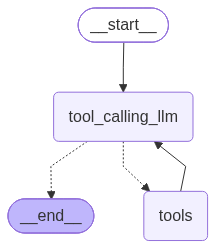

In [43]:
from IPython.display import Image, display

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [44]:
from langchain_core.messages import HumanMessage

response = graph.invoke({
    "messages": [
        HumanMessage(content="Find recent AI news and summarize it.")
    ]
})

for message in response["messages"]:
    message.pretty_print()

================================ Human Message =================================

Find recent AI news and summarize it.
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_ab4a5150-be14-4eec-894b-ecc0ca72c1e2)
 Call ID: fc_ab4a5150-be14-4eec-894b-ecc0ca72c1e2
  Args:
    query: recent AI news 2026 October
    search_depth: advanced
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026 October", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.facebook.com/jonathanjmast/posts/%F0%9D%97%94%F0%9D%97%9C-%F0%9D%97%A1%F0%9D%97%B2%F0%9D%98%84%F0%9D%98%80-%F0%9D%97%A7%F0%9D%97%B5%F0%9D%97%AE%F0%9D%98%81-%F0%9D%97%A0%F0%9D%97%AE%F0%9D%98%81%F0%9D%98%81%F0%9D%97%B2%F0%9D%97%BF%F0%9D%98%80-%F0%9D%98%81%F0%9D%97%BC-%F0%9D%97%98%F0%9D%97%BB%F0%9D%98%81%F0%9D%97%BF%F0%9D%97%B2%F0%9D%9

In [45]:
response = graph.invoke({
    "messages": [
        HumanMessage(content="What is 5 multiplied by 2?")
    ]
})

for message in response["messages"]:
    message.pretty_print()

================================ Human Message =================================

What is 5 multiplied by 2?
================================== Ai Message ==================================

5 multiplied by 2 equals **10**.


In [46]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 5 multiplied by 2?
================================== Ai Message ==================================

5 multiplied by 2 equals **10**.


In [47]:
response = graph.invoke({
    "messages": "What is 5 Multiply by 2"
})

for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is 5 Multiply by 2
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_4df2d0be-1ad0-4c03-a2ae-ad95b76fc5b4)
 Call ID: fc_4df2d0be-1ad0-4c03-a2ae-ad95b76fc5b4
  Args:
    a: 5
    b: 2
================================= Tool Message =================================
Name: multiply

10
================================== Ai Message ==================================

10


## React Agent Architecture

ReAct Agent workflow built successfully!


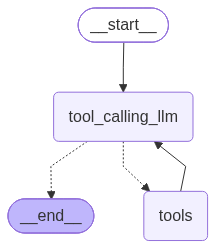

================================ Human Message =================================

What is 25 multiplied by 4?
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_c570b2d1-bc6d-4718-aa14-c5c5ac24930c)
 Call ID: fc_c570b2d1-bc6d-4718-aa14-c5c5ac24930c
  Args:
    a: 25
    b: 4
================================= Tool Message =================================
Name: multiply

100
================================== Ai Message ==================================

25 multiplied by 4 equals **100**.


In [50]:
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage
from langchain_groq import ChatGroq
from langchain_tavily import TavilySearch
from IPython.display import Image, display
from dotenv import load_dotenv

# 1. Load API keys from .env
load_dotenv()

# 2. Initialize LLM
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)

# 3. Create tools
search_tool = TavilySearch(max_results=3)

@tool
def multiply(a: int, b: int) -> int:
    """Multiply two integers and return the result."""
    return a * b

tools = [search_tool, multiply]

# 4. Bind tools to LLM
llm_with_tools = llm.bind_tools(tools)

# 5. Define the LLM node
def tool_calling_llm(state: MessagesState):
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}

# 6. Build the ReAct workflow
builder = StateGraph(MessagesState)

# Add nodes
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

# Add edges
builder.add_edge(START, "tool_calling_llm")

# Route to tools if the LLM requests a tool;
# otherwise, finish the workflow
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition,
    {
        "tools": "tools",
        END: END
    }
)

# Return to LLM after tool execution
builder.add_edge("tools", "tool_calling_llm")

# 7. Compile the graph
graph = builder.compile()

print("ReAct Agent workflow built successfully!")

# 8. Display workflow diagram
display(Image(graph.get_graph().draw_mermaid_png()))

# 9. Run the agent
response = graph.invoke({
    "messages": [
        HumanMessage(
            content="What is 25 multiplied by 4?"
        )
    ]
})

# 10. Display conversation and final answer
for message in response["messages"]:
    message.pretty_print()

## Adding Memory in Agentic Graph

ReAct Agent with Memory created successfully!


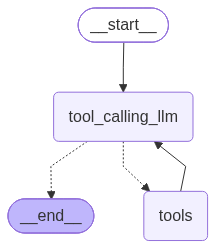

In [53]:
from dotenv import load_dotenv

from langchain_groq import ChatGroq
from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage

from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver

from IPython.display import Image, display

# 1. Load API keys
load_dotenv()

# 2. Initialize LLM
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)

# 3. Create tools
search_tool = TavilySearch(max_results=3)

@tool
def multiply(a: int, b: int) -> int:
    """Multiply two integers and return the product."""
    return a * b

tools = [search_tool, multiply]

# 4. Bind tools to LLM
llm_with_tools = llm.bind_tools(tools)

# 5. Define LLM node
def tool_calling_llm(state: MessagesState):
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}

# 6. Build graph
builder = StateGraph(MessagesState)

builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")

builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)

# After tool execution, return to LLM
builder.add_edge("tools", "tool_calling_llm")

# 7. Add memory/checkpointer
memory = InMemorySaver()

graph = builder.compile(checkpointer=memory)

print("ReAct Agent with Memory created successfully!")

# 8. Display workflow
display(Image(graph.get_graph().draw_mermaid_png()))

In [54]:
config = {
    "configurable": {
        "thread_id": "ankur-session-1"
    }
}

response = graph.invoke(
    {
        "messages": [
            HumanMessage(
                content="Find recent AI news and then multiply 5 by 10. Summarize both results."
            )
        ]
    },
    config=config
)

for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Find recent AI news and then multiply 5 by 10. Summarize both results.
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_1c8ccc28-594c-41e7-b29c-defa27de0f30)
 Call ID: fc_1c8ccc28-594c-41e7-b29c-defa27de0f30
  Args:
    query: latest AI news 2026
    search_depth: advanced
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-september-2026", "title": "The latest AI news we announced in September 2026", "content": "Voice\n\nSpeed 0.75X 1X 1.5X 2X\n\n Read AI-generated summary \n\n   Check out the latest AI news from September 2026 in our monthly roundup.\n   Gemini 4 Argon leads our new frontier mode

In [55]:
new_config = {
    "configurable": {
        "thread_id": "ankur-session-2"
    }
}

response = graph.invoke(
    {
        "messages": [
            HumanMessage(
                content="What did I ask you in my previous conversation?"
            )
        ]
    },
    config=new_config
)

for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What did I ask you in my previous conversation?
================================== Ai Message ==================================

You asked: **“What did I ask you in my previous conversation?”**


In [56]:
from langchain_core.messages import HumanMessage

# Use the SAME thread_id as your previous conversation
config = {
    "configurable": {
        "thread_id": "ankur-session-1"
    }
}

response = graph.invoke(
    {
        "messages": [
            HumanMessage(
                content=(
                    "Search our previous conversation history. "
                    "What AI news did I ask you to find, "
                    "and what multiplication did I ask you to perform?"
                )
            )
        ]
    },
    config=config
)

# Display the latest answer
response["messages"][-1].pretty_print()

================================== Ai Message ==================================

You asked me to:

1. **Find recent AI news** – I searched for and reported on the latest AI developments from September 2026 (Google’s Gemini 4 Argon, new voice models, scientific breakthroughs, etc.), July 2026 (new Gemini agents, robotics, wildfire‑satellite updates, music‑generation model), and a September 2026 policy story (Trump’s “self‑policing” AI accord).

2. **Multiply 5 by 10** – I performed the multiplication and gave the result **50**.


In [57]:
# Retrieve saved conversation state
state = graph.get_state(config)

for message in state.values.get("messages", []):
    message.pretty_print()

================================ Human Message =================================

Find recent AI news and then multiply 5 by 10. Summarize both results.
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_1c8ccc28-594c-41e7-b29c-defa27de0f30)
 Call ID: fc_1c8ccc28-594c-41e7-b29c-defa27de0f30
  Args:
    query: latest AI news 2026
    search_depth: advanced
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-september-2026", "title": "The latest AI news we announced in September 2026", "content": "Voice\n\nSpeed 0.75X 1X 1.5X 2X\n\n Read AI-generated summary \n\n   Check out the latest AI news from September 2026 in our monthly roundup.\n   Gemini 4 Argon leads our new frontier mode

In [58]:
response=graph.invoke({"message":"hey what is my name"},config=config)

print(response['messages'][-1].content)

You asked me to:

1. **Find recent AI news** – I searched for and reported on the latest AI developments from September 2026 (Google’s Gemini 4 Argon, new voice‑centric Gemini models, scientific breakthroughs, etc.), July 2026 (new Gemini agents, robotics, wildfire‑satellite updates, music‑generation model), and a September 2026 policy story (Trump’s “self‑policing” AI accord).

2. **Multiply 5 by 10** – I performed the multiplication and gave the result **50**.


Name saved in this conversation!
Got it, Ankur! I’ll remember that. How can I help you today?

Agent's answer:
================================== Ai Message ==================================

Your name is Ankur.


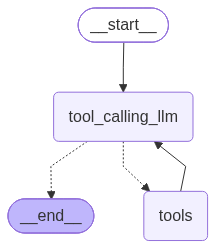

In [59]:
from dotenv import load_dotenv

from langchain_groq import ChatGroq
from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage

from langgraph.graph import StateGraph, START, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver

from IPython.display import Image, display

load_dotenv()

# 1. Initialize LLM
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)

# 2. Create tools
search_tool = TavilySearch(max_results=3)

@tool
def multiply(a: int, b: int) -> int:
    """Multiply two integers."""
    return a * b

tools = [search_tool, multiply]

# 3. Bind tools
llm_with_tools = llm.bind_tools(tools)

# 4. LLM node
def tool_calling_llm(state: MessagesState):
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}

# 5. Build LangGraph
builder = StateGraph(MessagesState)

builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm", tools_condition)
builder.add_edge("tools", "tool_calling_llm")

# 6. Add short-term memory
memory = InMemorySaver()
graph = builder.compile(checkpointer=memory)

# 7. Set conversation ID
config = {
    "configurable": {
        "thread_id": "ankur-session-1"
    }
}

# 8. Save your name in the conversation
response = graph.invoke(
    {
        "messages": [
            HumanMessage(
                content="My name is Ankur. Please remember my name."
            )
        ]
    },
    config=config
)

print("Name saved in this conversation!")
print(response["messages"][-1].content)

# 9. Ask the agent your name
response = graph.invoke(
    {
        "messages": [
            HumanMessage(content="What is my name?")
        ]
    },
    config=config
)

print("\nAgent's answer:")
response["messages"][-1].pretty_print()

# 10. Display workflow
display(Image(graph.get_graph().draw_mermaid_png()))

In [60]:
response = graph.invoke(
    {
        "messages": [
            HumanMessage(
                content="What is my name, and what tools can you use?"
            )
        ]
    },
    config=config
)

response["messages"][-1].pretty_print()

================================== Ai Message ==================================

Your name is **Ankur**.

I can also use the following tools to help you:

| Tool | Purpose |
|------|---------|
| **`tavily_search`** | Performs web searches (with advanced options like date ranges, domain filters, image inclusion, etc.) and returns URLs, snippets, and citations. |
| **`multiply`** | Calculates the product of two integers. |

Let me know if you’d like to use either of these!


## Streming

In [61]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

In [62]:
def superbot(state:state):
    return {"message":[llm.invoke(state['message'])]}

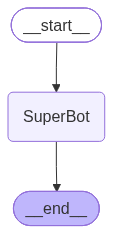

In [63]:
graph=StateGraph(State)

## Node
graph.add_node("SuperBot",superbot)

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)

graph_builder=graph.compile(checkpointer=memory)

## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [1]:
from langgraph.graph import MessagesState

def superbot(state: MessagesState):
    response = llm.invoke(state["messages"])
    return {"messages": [response]}

In [2]:
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

graph_builder = StateGraph(MessagesState)

graph_builder.add_node("SuperBot", superbot)

graph_builder.add_edge(START, "SuperBot")
graph_builder.add_edge("SuperBot", END)

memory = InMemorySaver()

graph = graph_builder.compile(checkpointer=memory)

Graph created successfully!


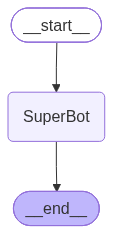

Bot: Hey Ankur! 👋 It’s great to meet a fellow cricket fan. What’s your favorite team or player? Or maybe you’ve got a memorable match you’d love to talk about? I’m all ears!


In [4]:
from dotenv import load_dotenv
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from IPython.display import Image, display

# 1. Load API key from .env
load_dotenv()

# 2. Initialize LLM
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)

# 3. Define chatbot node
def superbot(state: MessagesState):
    response = llm.invoke(state["messages"])
    return {"messages": [response]}

# 4. Build graph
builder = StateGraph(MessagesState)

builder.add_node("SuperBot", superbot)
builder.add_edge(START, "SuperBot")

# 5. Add memory
memory = InMemorySaver()

# 6. Compile graph
graph = builder.compile(checkpointer=memory)

print("Graph created successfully!")

# 7. Visualize workflow
display(Image(graph.get_graph().draw_mermaid_png()))

# 8. Set conversation ID
config = {
    "configurable": {
        "thread_id": "ankur-session-1"
    }
}

# 9. Send first message
response = graph.invoke(
    {
        "messages": [
            HumanMessage(
                content="Hi, my name is Ankur and I love cricket."
            )
        ]
    },
    config=config
)

print("Bot:", response["messages"][-1].content)